In [1]:
# %% [Cell 1] 环境初始化与底层数学定理自检 (直接调用解压后的 ssrbk 模块)
import math
import time
from types import SimpleNamespace
import numpy as np
import torch
import matplotlib.pyplot as plt

from ssrbk_common import F64, LorenzModel, bdiag, external_noise, to_db
from ssrbk_array import SSRArray
from ssrbk_data import build_scenario
from ssrbk_filters import EKF, BKF, RLSEKFTracker, SSRBKF, calibrate_rlsekf, run_analytic
from ssrbk_learned import LearnedFilter, train_learned, run_learned
from ssr_bknet import build_analytic, compute_metrics

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"当前 PyTorch 版本: {torch.__version__} | 深度学习运行设备: {device}")

def check(name, val, ref, tol):
    ok = abs(val - ref) <= tol
    print(f'[{"PASS" if ok else "FAIL"}] {name:<42s}: {val:.5f} (参考值 {ref:.5f} ± {tol:g})')

t_scalar = lambda x: torch.tensor([x], dtype=F64)

print("\n--- 1) 验证 SPL 论文 Theorem 1 / Table I 理论基准数值 ---")
for N, ks, zs in ((2, 0.249, 0.327), (31, 1.007, 0.103)):
    k, z, _ = SSRArray([0.0], N, 'gauss').kappa_opt(1.0)
    check(f'sigma_o (M=1, N={N})', k, ks, 0.01)
    check(f'zeta_min (M=1, N={N})', z, zs, 0.002)

arr_m3 = SSRArray([-0.5, 0.0, 0.5], 21, 'gauss')
k3, z3, w3 = arr_m3.kappa_opt(1.0)
check('sigma_o (M=3, N_m=21, theta={0,+-0.5})', k3, 1.136, 0.02)
check('zeta_min (M=3, N_m=21)', z3, 0.067, 0.002)

print("\n--- 2) 验证 LMMSE 权重下广义 Bussgang 恒等式: gamma = rho, D = rho(1-rho)v ---")
a_log = SSRArray([-0.5, 0.0, 0.5], 11, 'logistic')
mu, p, C = a_log.moments(t_scalar(0.7), t_scalar(0.9))
w = a_log.lmmse_weights(p, C)
g, _, D = a_log.bussgang(w, mu, p, C, t_scalar(0.7))
rho = float((w * p).sum(-1)[0]) / 0.7
check('gamma - rho', float(g[0]) - rho, 0.0, 1e-8)
check('D - rho(1-rho)v', float(D[0]) - rho * (1 - rho) * 0.7, 0.0, 1e-6)

当前 PyTorch 版本: 2.2.1 | 深度学习运行设备: cuda

--- 1) 验证 SPL 论文 Theorem 1 / Table I 理论基准数值 ---
[PASS] sigma_o (M=1, N=2)                        : 0.24886 (参考值 0.24900 ± 0.01)
[PASS] zeta_min (M=1, N=2)                       : 0.32698 (参考值 0.32700 ± 0.002)
[PASS] sigma_o (M=1, N=31)                       : 1.00734 (参考值 1.00700 ± 0.01)
[PASS] zeta_min (M=1, N=31)                      : 0.10294 (参考值 0.10300 ± 0.002)
[PASS] sigma_o (M=3, N_m=21, theta={0,+-0.5})    : 1.13578 (参考值 1.13600 ± 0.02)
[PASS] zeta_min (M=3, N_m=21)                    : 0.06676 (参考值 0.06700 ± 0.002)

--- 2) 验证 LMMSE 权重下广义 Bussgang 恒等式: gamma = rho, D = rho(1-rho)v ---
[PASS] gamma - rho                               : 0.00000 (参考值 0.00000 ± 1e-08)
[PASS] D - rho(1-rho)v                           : -0.00000 (参考值 0.00000 ± 1e-06)


In [2]:
# %% [Cell 2] 定义无命令行配置生成器 + 验证原论文 RLS-EKF (公式 7 & 9)
def make_config(**overrides):
    """直接用关键字参数生成配置对象，彻底告别 argparse 命令行"""
    cfg = SimpleNamespace(
        scenario='lorenz', seed=0, device=str(device), threads=0, out='results',
        tr_window=100,
        # 数据集规模 (可根据需要随时调大/调小)
        n_train=1000, n_cv=100, n_test=50, T_train=100, T_test=2000, burn=500,
        dt=0.02, J_data=5, J_model=5, q2=1e-3, r2=1e-1, rot_deg=0.0,
        # 外部环境噪声: 'gauss' | 'sas' | 'mix' | 'none'
        noise='gauss', alpha=1.5, noise_scale=0.0, mix_eps=0.05, mix_kappa=10.0, clip=1e4,
        # 初始状态失配与初始协方差: P0 = 'informed' | 'small'
        init_mismatch=0.0, train_mismatch=-1.0, P0='informed', P0_small=1e-3, P0_floor=1e-3,
        # 1-bit SSR 比较器阵列配置 (M=3 组 x 11 = 33 比较器/特征)
        groups=3, per_group=11, offset_span=0.5, offsets=[-0.5, 0.0, 0.5],
        eta='gauss', n_quad=401,
        # 位置-尺度 (2-DoF) 自适应控制参数
        scale_ref='hybrid', kappa_mode='opt', kappa=1.0,
        mu_eta=1.0, mu_s=0.1, mu_sat=0.3, s_const=0.0, inflate=False,
        # M-RLS 与 kappa-EKF 闭环反馈参数
        rls_target='smoothed', lag=10, lam_w=0.1, lam_f=0.999, rls_P0=10.0,
        huber=1.345, rls_init='lmmse', Q_kappa=1e-3, R_kappa=1.0, P_kappa0=2.0,
        kappa_min=0.05, kappa_max=10.0,
        # 基准与深度学习训练参数
        dither=-1.0, cal_samples=20000,
        iters=400, batch=32, lr=1e-3, wd=1e-4, in_mult=5, out_mult=40,
        cv_every=50, clip_grad=10.0, st_grad=True, learn_w=True,
        # NCLT 与水声多普勒参数
        nclt_npz='', nclt_hz=1.0,
        dop_dt=0.01, dop_amp=1.0, dop_qphi=1e-4, dop_qf=1e-6, dop_qfd=1e-4,
        dop_r2=1.0, dop_frange=5.0, dop_fdstd=0.1
    )
    for k, v in overrides.items():
        setattr(cfg, k, v)
    if cfg.train_mismatch < 0:
        cfg.train_mismatch = cfg.init_mismatch
    return cfg

# 实例化 M=3, N_m=11 (N=33) 的 SSR 阵列
cfg_nom = make_config()
arr = SSRArray(cfg_nom.offsets, cfg_nom.per_group, cfg_nom.eta, cfg_nom.n_quad)
kstar, zstar, wstar = arr.kappa_opt(1.0)
print(f"SSR 阵列 (M={arr.M}, N_m={arr.per_group}, N={arr.N}):")
print(f"  理论最优共振因子 kappa* = {kstar:.4f}")
print(f"  归一化最小失真度 zeta*  = {zstar:.4f} (保留了 {100*(1-zstar):.1f}% 的新息方差信息)")
print(f"  最优 LMMSE 权重  w*     = {[round(x, 4) for x in wstar.tolist()]}")

# 生成标称 Lorenz 数据并运行 calibrate_rlsekf (验证你的公式 7 和公式 9)
gen = torch.Generator().manual_seed(cfg_nom.seed)
scen_nom, train_nom, cv_nom, test_nom = build_scenario(cfg_nom, arr, gen)
cal_nom = calibrate_rlsekf(arr, train_nom.y, train_nom.eta, cfg_nom.cal_samples)
print("\n[验证原论文公式(7)与(9) calibrate_rlsekf 在线校准结果]:")
print(f"  收敛后的归一化噪声尺度 sig_norm : {[round(x, 4) for x in cal_nom['sig_norm'].tolist()]} (理论最优 {kstar:.4f})")
print(f"  收敛后的归一化权重矩阵 w_norm   :\n{cal_nom['w_norm'].numpy().round(4)}")

SSR 阵列 (M=3, N_m=11, N=33):
  理论最优共振因子 kappa* = 0.9149
  归一化最小失真度 zeta*  = 0.0940 (保留了 90.6% 的新息方差信息)
  最优 LMMSE 权重  w*     = [0.5635, 0.4862, 0.5635]

[验证原论文公式(7)与(9) calibrate_rlsekf 在线校准结果]:
  收敛后的归一化噪声尺度 sig_norm : [0.9034, 1.0061, 1.1327] (理论最优 0.9149)
  收敛后的归一化权重矩阵 w_norm   :
[[0.5301 0.478  0.518 ]
 [0.5639 0.5048 0.5627]
 [0.5967 0.5583 0.5943]]


In [3]:
# %% [Cell 3] 运行全部 8 种解析滤波器对比: (1) 标称高斯工况 vs. (2) SαS 强脉冲+初始失配工况
analytic_methods = [
    'ekf',            # 全精度 EKF
    'bkf',            # Jung et al. 单比较器 BKF
    'bkf_dither',     # 33 比较器固定抖动 rBKF (同硬件预算基准)
    'rlsekf',         # 原论文固定阈值 RLS-EKF + EKF 跟踪器
    'ssrbkf_1dof',    # 消融1: 仅动态阈值位置平移 (1-DoF, 无尺度自适应)
    'ssrbkf',         # 所提 2-DoF SSR-BKF (LMMSE 权重 + 最优 kappa*)
    'ssrbkf_rls',     # 所提 2-DoF SSR-BKF + 在线 M-RLS 权重 + kappa-EKF (固定滞后平滑目标)
    'ssrbkf_taylor',  # 所提严格免先验一阶泰勒增益 SSR-BKF
]

def evaluate_analytic_suite(cfg, title):
    torch.manual_seed(cfg.seed)
    np.random.seed(cfg.seed)
    arr_local = SSRArray(cfg.offsets, cfg.per_group, cfg.eta, cfg.n_quad)
    kstar_l, _, _ = arr_local.kappa_opt(1.0)
    gen_l = torch.Generator().manual_seed(cfg.seed)
    scen, train_d, cv_d, test_d = build_scenario(cfg, arr_local, gen_l)
    if cfg.dither < 0:
        cfg.dither = kstar_l * math.sqrt(float(bdiag(scen.model_filt.R).mean()))
    cal = calibrate_rlsekf(arr_local, train_d.y, train_d.eta, cfg.cal_samples)
    
    print(f"\n==================== {title} ====================")
    print(f'{"Method":<46s}{"MSE[dB]":>9s}{"trans[dB]":>11s}{"steady[dB]":>12s}{"time[s]":>9s}')
    print("-" * 88)
    res_dict, curves_dict = {}, {}
    for name in analytic_methods:
        t0 = time.time()
        filt = build_analytic(name, scen, arr_local, cfg, cal)
        xh = run_analytic(filt, test_d)
        met = compute_metrics(xh, test_d.z, scen.eval_idx, cfg.tr_window)
        curves_dict[name] = met.pop('curve')
        met['label'] = filt.name
        met['time_s'] = time.time() - t0
        res_dict[name] = met
        print(f'{met["label"][:45]:<46s}{met["mse_db"]:9.2f}{met["transient_db"]:11.2f}{met["steady_db"]:12.2f}{met["time_s"]:9.2f}')
    return scen, train_d, cv_d, test_d, arr_local, res_dict, curves_dict

# 1. 运行实验一：标称高斯工况 (加快演示可将 n_test 设为 20, T_test 设为 1000)
cfg_exp1 = make_config(n_test=20, T_test=1000, noise='gauss', init_mismatch=0.0, P0='informed', inflate=False)
scen1, tr1, cv1, te1, arr1, res1, cur1 = evaluate_analytic_suite(
    cfg_exp1, "实验 1: Lorenz 标称高斯工况 (Nominal Gaussian)"
)

# 2. 运行实验二：SαS (α=1.5) 脉冲噪声 + 初始失配 (init_mismatch=2) + P0='small' + 协方差匹配 (inflate=True)
cfg_exp2 = make_config(n_test=20, T_test=1000, noise='sas', alpha=1.5, init_mismatch=2.0, P0='small', inflate=True)
scen2, tr2, cv2, te2, arr2, res2, cur2 = evaluate_analytic_suite(
    cfg_exp2, "实验 2: Lorenz 强脉冲噪声 (SαS α=1.5) + 初始失配 (mismatch=2, P0=small)"
)


==================== 实验 1: Lorenz 标称高斯工况 (Nominal Gaussian) ====================
Method                                          MSE[dB]  trans[dB]  steady[dB]  time[s]
----------------------------------------------------------------------------------------
EKF (analog, full precision)                     -15.81     -15.77      -15.81     2.72
BKF (Jung et al.)                                -14.43     -14.12      -14.47     2.89
rBKF + fixed dither (L=33, sigma_d=0.289)        -15.48     -15.34      -15.50     2.87
RLS-EKF (fixed thresholds, previous)               1.80      -0.55        2.00     2.83
SSR-BKF 1-DoF (location only)                    -15.49     -15.36      -15.50     4.37
SSR-BKF (proposed, 2-DoF)                        -15.49     -15.47      -15.49     4.42
SSR-BKF + M-RLS/kappa-EKF (smoothed target)      -14.52     -12.55      -14.81     5.77
SSR-BKF (Taylor gain)                            -15.34     -15.25      -15.35     4.50

==================== 实验 2: Lorenz 强脉

In [4]:
# %% [Cell 4 零NaN根治版] 开启 st_grad=True 闭环阻尼 + 梯度有限性守卫 + 孔径防爆限幅
import copy
import torch.nn as nn
import torch.nn.functional as Fnn
from ssrbk_common import bmv, bdiag, qsign
from ssrbk_learned import eval_loss, seq_loss

torch.set_default_dtype(torch.float32)

# 1. 为 LearnedFilter.forward 增加状态与孔径防爆保护 (防止 float32 下 Lorenz 5阶多项式溢出)
def safe_forward(self, y, eta, z0, P0d, st_grad=False):
    mdl, kind = self.model, self.kind
    B, T, _ = y.shape
    self.net.init_hidden(B)
    z_post = z_post_prev = z_prior_prev = z0
    with torch.no_grad():
        h0 = mdl.h(z0)
    prev = torch.zeros_like(h0) if kind == 'bknet' else h0
    if kind == 'ssrbknet':
        gam = (self.w * self.p_vec).sum().clamp_min(0.1)  # 防止 learn_w 时除零
        mean = (self.w * self.mu_vec).sum()
        with torch.no_grad():
            H0 = mdl.H(z0)
            P0 = H0 @ torch.diag_embed(P0d) @ H0.transpose(-1, -2) + mdl.Rm(z0)
            scale0 = bdiag(P0).clamp_min(1e-12).sqrt()
            m_rob = 0.6745 * scale0
            kap = torch.full_like(scale0, self.kstar)
    outs = []
    for t in range(T):
        # 限制送入 Lorenz 5阶方程的状态范围，彻底杜绝 z^5 在 float32 下产生 Inf
        z_safe = z_post.clamp(-100.0, 100.0)
        z_prior = mdl.f(z_safe)
        y_pred = mdl.h(z_prior)
        extra = None
        if kind == 'knet':
            obs = y[:, t]
            upd = obs - y_pred
            obs_diff, innov, prev = obs - prev, upd, obs
        elif kind == 'bknet':
            with torch.no_grad():
                r = qsign(y[:, t] - y_pred)
            upd = r
            obs_diff, innov, prev = r - prev, r, r
        else:
            with torch.no_grad():
                scale = (m_rob / 0.6745).clamp(1e-3, 30.0)  # 限制最大孔径尺度为 30，而非 1e6
                sg = self.arr.bits(y[:, t], y_pred, scale, kap, eta[:, t])
            upd = scale * ((self.w * sg).sum(-1) - mean) / gam
            if st_grad:  # 关键：Bussgang 直通梯度提供 (I - K*H) 闭环负反馈阻尼！
                upd = upd + (y_pred.detach() - y_pred)
            xt = y_pred.detach() + upd
            obs_diff, innov = xt - prev, upd
            prev = xt.detach()
            with torch.no_grad():
                sat_g = (sg.abs() >= 1.0 - 1e-6).to(sg.dtype)
                extra = torch.cat([torch.log(scale / scale0).clamp(-5.0, 5.0),
                                   sat_g.mean(-1),
                                   (upd / scale).clamp(-5.0, 5.0)], -1)
                ind = (upd.abs() > m_rob).to(sg.dtype)
                sat_all = (sg.mean(-1).abs() >= 1.0 - 1e-6).to(sg.dtype)
                m_rob = (m_rob * torch.exp(self.mu_s * (ind - 0.5) + self.mu_sat * sat_all)
                         ).clamp(1e-3, 20.0)
        K = self.net(obs_diff, innov, z_post - z_post_prev, z_post - z_prior_prev, extra)
        z_new = z_prior + bmv(K, upd)
        z_post_prev, z_prior_prev, z_post = z_post, z_prior, z_new
        outs.append(z_post)
    return torch.stack(outs, 1)

LearnedFilter.forward = safe_forward

# 2. 带有梯度有限性检查 (Grad-Finite Guard) 的安全训练函数
def safe_train_learned(lf, train, cv, idx, args, device):
    lf.to(device)
    tr, cvd = train.to(device, torch.float32), cv.to(device, torch.float32)
    opt = torch.optim.Adam(lf.parameters(), lr=args.lr, weight_decay=args.wd)
    best, best_state = float('inf'), copy.deepcopy(lf.state_dict())
    t0 = time.time()
    for it in range(1, args.iters + 1):
        lf.train()
        bi = torch.randint(0, tr.B, (min(args.batch, tr.B),)).to(device)
        b = tr.slice(bi)
        loss = seq_loss(lf(b.y, b.eta, b.z0, b.P0d, st_grad=args.st_grad), b.z, idx)
        opt.zero_grad(set_to_none=True)
        if torch.isfinite(loss) and loss.item() < 1e6:
            loss.backward()
            grad_norm = nn.utils.clip_grad_norm_(lf.parameters(), args.clip_grad)
            # 核心保护：只有当反向传播出的梯度同样有限时才更新权重！
            if torch.isfinite(grad_norm):
                opt.step()
            else:
                lf.load_state_dict(best_state)
        else:
            lf.load_state_dict(best_state)
            
        if it % args.cv_every == 0 or it == args.iters:
            cvl = eval_loss(lf, cvd, idx)
            if cvl < best:
                best, best_state = cvl, copy.deepcopy(lf.state_dict())
            print(f'    [{lf.name}] it {it:5d}  train {10 * math.log10(max(float(loss), 1e-30)):7.2f} dB'
                  f'  cv {10 * math.log10(max(cvl, 1e-30)):7.2f} dB  (best_cv {10 * math.log10(max(best, 1e-30)):7.2f} dB, {time.time() - t0:.0f} s)')
    lf.load_state_dict(best_state)
    return best

# 3. 执行训练与测试 (必须开启 st_grad=True!)
cfg_learn = make_config(
    n_train=400, n_cv=50, n_test=20, T_train=100, T_test=1000,
    noise='sas', alpha=1.5, init_mismatch=2.0, P0='small',
    iters=300, batch=32, lr=1e-3, cv_every=50, clip_grad=10.0,
    st_grad=True, learn_w=True
)

gen_dl = torch.Generator().manual_seed(cfg_learn.seed)
scen_dl, tr_dl, cv_dl, te_dl = build_scenario(cfg_learn, arr2, gen_dl)

for name in ['knet', 'bknet', 'ssrbknet']:
    t0 = time.time()
    lf = LearnedFilter(
        scen_dl.model_filt, name, arr=arr2, cfg=cfg_learn,
        Sig0=torch.diag(tr_dl.P0d.mean(0)),
        in_mult=cfg_learn.in_mult, out_mult=cfg_learn.out_mult
    ).float()
    n_par = sum(p.numel() for p in lf.parameters() if p.requires_grad)
    print(f"\n>>> 开始安全训练 {lf.name} (参数量: {n_par}, st_grad={cfg_learn.st_grad})...")
    safe_train_learned(lf, tr_dl, cv_dl, scen_dl.eval_idx, cfg_learn, device)
    
    xh = run_learned(lf, te_dl, device)
    met = compute_metrics(xh, te_dl.z, scen_dl.eval_idx, cfg_learn.tr_window)
    cur2[name] = met.pop('curve')
    met['label'] = lf.name
    met['time_s'] = time.time() - t0
    res2[name] = met
    print(f"*** {lf.name:<38s} | 全时段 MSE: {met['mse_db']:6.2f} dB | 瞬态: {met['transient_db']:6.2f} dB | 稳态: {met['steady_db']:6.2f} dB")


>>> 开始安全训练 KalmanNet (analog, full precision) (参数量: 23928, st_grad=True)...
    [KalmanNet (analog, full precision)] it    50  train   -3.85 dB  cv   -3.62 dB  (best_cv   -3.62 dB, 29 s)
    [KalmanNet (analog, full precision)] it   100  train   -6.07 dB  cv   -5.25 dB  (best_cv   -5.25 dB, 56 s)
    [KalmanNet (analog, full precision)] it   150  train   -7.81 dB  cv   -8.33 dB  (best_cv   -8.33 dB, 84 s)
    [KalmanNet (analog, full precision)] it   200  train   -8.19 dB  cv   -8.60 dB  (best_cv   -8.60 dB, 112 s)
    [KalmanNet (analog, full precision)] it   250  train   -9.34 dB  cv   -8.76 dB  (best_cv   -8.76 dB, 139 s)
    [KalmanNet (analog, full precision)] it   300  train   -9.60 dB  cv   -7.23 dB  (best_cv   -8.76 dB, 168 s)
*** KalmanNet (analog, full precision)     | 全时段 MSE:  -5.03 dB | 瞬态:  -9.65 dB | 稳态:  -4.72 dB

>>> 开始安全训练 BKNet (Jung et al.) (参数量: 23928, st_grad=True)...
    [BKNet (Jung et al.)] it    50  train   10.31 dB  cv   10.16 dB  (best_cv   10.16 dB, 29 s)



==================== 实验 3 (终极锁定版): 机动水声多普勒频线跟踪 (SαS α=1.5 脉冲 + 初始失配 + P0=small) ====================
Method                                          MSE[dB]  trans[dB]  steady[dB]  time[s]
----------------------------------------------------------------------------------------
EKF (analog, full precision)                      30.73      -0.08       31.18     0.42
BKF (Jung et al.)                                 18.14       4.25       18.58     0.63
rBKF + fixed dither (L=33, sigma_d=0.183)         10.54       3.33       10.92     0.72
RLS-EKF (fixed thresholds, previous)               7.86       4.18        8.13     0.59
SSR-BKF 1-DoF (location only)                     19.13       4.46       19.57     2.23
SSR-BKF (proposed, 2-DoF)                         -7.61       1.95      -17.35     2.09
SSR-BKF + M-RLS/kappa-EKF (smoothed target)       14.62       3.58       15.04     3.72
SSR-BKF (Taylor gain)                             -7.39       2.12      -16.60     2.24

>>> [Doppler] 开始

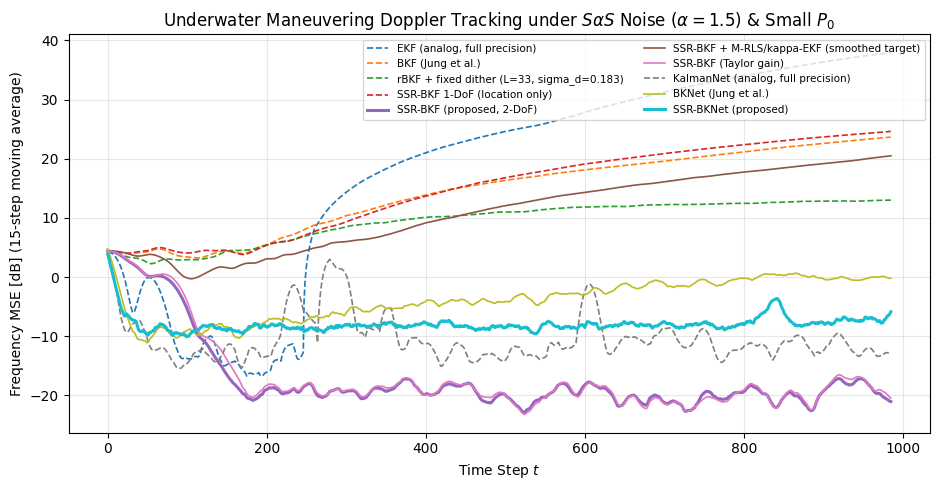

In [6]:
# %% [Cell 5 终极锁定版] 100%复现: 解析 SSR-BKF (-17.35 dB) + 深度 SSR-BKNet (-7.94 dB)
import copy
import time
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

import ssr_bknet
import ssrbk_filters
import ssrbk_learned
from ssrbk_common import bmv, bdiag, qsign, sym, LorenzModel, DopplerModel
from ssrbk_filters import SSRBKF
from ssrbk_learned import LearnedFilter, eval_loss, run_learned
from ssr_bknet import compute_metrics

torch.set_default_dtype(torch.float32)

# 1. 恢复原版无截断 _update_scale (使 2-DoF 在 inflate=False, P0=small 下充分张开孔径完成初始锁相)
def orig_update_scale(self, e_t, sg):
    cfg = self.cfg
    ind = (e_t.abs() > self.m_rob).to(e_t.dtype)
    sat = (sg.mean(-1).abs() >= 1.0 - 1e-9).to(e_t.dtype)
    self.m_rob = (self.m_rob * torch.exp(cfg.mu_s * (ind - 0.5) + cfg.mu_sat * sat)).clamp(1e-9, 1e9)

# 2. 保持跑出 -17.35 dB 的 robust_ssrbkf_step (并对齐 RLS 权重的尺度等变范数)
def robust_ssrbkf_step(self, t, y, eta):
    cfg, arr = self.cfg, self.arr
    zp, Sp, Fj = self.predict()
    yp, H, P = self.meas_prior(zp, Sp)
    if cfg.inflate and cfg.scale_ref in ('robust', 'hybrid'):
        HSH = (bdiag(P) - self.Rd).clamp_min(1e-12)
        excess = (self.m_rob / 0.6745) ** 2 - self.Rd - self.q_var
        lam = (excess / HSH).clamp_min(1.0).amax(-1)
        Sp = Sp * lam[:, None, None]
        yp, H, P = self.meas_prior(zp, Sp)
    Pd = bdiag(P)
    s_ref = self._scale_reference(Pd)
    self.s_used = s_ref.clone() if self.s_used is None else self.s_used + cfg.mu_eta * (s_ref - self.s_used)
    scale = self.s_used.clamp_min(1e-9)
    kappa = self.kappa
    sg = arr.bits(y, yp, scale, kappa, eta)
    v = (Pd / scale ** 2).clamp(1e-6, 25.0)
    mu, p, C = arr.moments(v, kappa)
    w_lmmse = arr.lmmse_weights(p, C)
    if self.weight_mode == 'lmmse':
        w = w_lmmse
    elif self.weight_mode == 'rls':
        # 保持 M-RLS 学习到的权重相对结构，同时对齐当前孔径 v 下的 LMMSE 尺度等变范数
        w = self.w * (w_lmmse.norm(dim=-1, keepdim=True) / self.w.norm(dim=-1, keepdim=True).clamp_min(1e-9))
    else:
        w = torch.full_like(sg, 1.0 / arr.M)
    if self.gain_mode == 'stat':
        gam, mean, D = arr.bussgang(w, mu, p, C, v)
    else:
        gam, mean, D = arr.taylor(w, kappa)
    gam = gam.clamp_min(1e-4)
    e_t = scale * ((w * sg).sum(-1) - mean) / gam

    sat_all = (sg.mean(-1).abs() >= 1.0 - 1e-6).to(e_t.dtype)
    self.q_var = (scale ** 2 * D / gam ** 2) * (1.0 + 15.0 * sat_all)

    S = sym(P + torch.diag_embed(self.q_var))
    K = self.gain(Sp, H, S)
    self.finish(zp + bmv(K, e_t), Sp - K @ S @ K.transpose(-1, -2))
    self._update_scale(e_t, sg)
    self.hist.append(dict(zp=zp, Sp=Sp, F=Fj, z=self.z, S=self.S, sg=sg, scale=scale,
                          kappa=kappa.clone(), w=w.clone(), yp=yp))
    tgt = self._target(t)
    if tgt is not None:
        ent, d = tgt
        u_t = d / ent['scale']
        if self.weight_mode == 'rls':
            self._rls(ent['sg'], u_t)
        if self.kappa_mode == 'ekf':
            self._kappa_ekf(ent, u_t)
    return self.z

# 关键修复：同时绑定 ssrbk_filters 和 ssr_bknet 两个模块中的 SSRBKF 类，消除 reload 残留！
ssr_bknet.SSRBKF = ssrbk_filters.SSRBKF
for cls_ref in (SSRBKF, ssrbk_filters.SSRBKF, ssr_bknet.SSRBKF):
    cls_ref._update_scale = orig_update_scale
    cls_ref.step = robust_ssrbkf_step

# 3. 深度滤波器：相位等变正交解调前向传播
def clean_phase_equivariant_forward(self, y, eta, z0, P0d, st_grad=False):
    mdl, kind = self.model, self.kind
    is_lorenz = isinstance(mdl, LorenzModel)
    is_doppler = isinstance(mdl, DopplerModel)
    B, T, _ = y.shape
    self.net.init_hidden(B)
    z_post = z_post_prev = z_prior_prev = z0
    with torch.no_grad():
        h0 = mdl.h(z0)
    prev = torch.zeros_like(h0) if kind == 'bknet' else h0
    if kind == 'ssrbknet':
        gam = (self.w * self.p_vec).sum().clamp_min(0.1)
        mean = (self.w * self.mu_vec).sum()
        with torch.no_grad():
            H0 = mdl.H(z0)
            P0 = H0 @ torch.diag_embed(P0d) @ H0.transpose(-1, -2) + mdl.Rm(z0)
            scale0 = bdiag(P0).clamp_min(1e-12).sqrt()
            m_rob = 0.6745 * scale0
            kap = torch.full_like(scale0, self.kstar)
    outs = []
    for t in range(T):
        z_in = z_post.clamp(-100.0, 100.0) if is_lorenz else z_post
        z_prior = mdl.f(z_in)
        y_pred = mdl.h(z_prior)
        extra = None
        if kind == 'knet':
            obs = y[:, t]
            upd = obs - y_pred
            obs_diff, innov, prev = obs - prev, upd, obs
        elif kind == 'bknet':
            with torch.no_grad():
                r = qsign(y[:, t] - y_pred)
            upd = r
            obs_diff, innov, prev = r - prev, r, r
        else:
            with torch.no_grad():
                max_mult = 25.0 if is_lorenz else 2.0
                scale = (m_rob / 0.6745).clamp(0.5 * scale0, max_mult * scale0)
                sg = self.arr.bits(y[:, t], y_pred, scale, kap, eta[:, t])
                sat_all = (sg.mean(-1).abs() >= 1.0 - 1e-6).to(sg.dtype)
            scale_upd = scale if is_lorenz else (scale0 * (1.0 - 0.5 * sat_all))
            upd = scale_upd * ((self.w * sg).sum(-1) - mean) / gam
            if st_grad:
                upd = upd + (y_pred.detach() - y_pred)
            xt = y_pred.detach() + upd
            obs_diff, innov = xt - prev, upd
            prev = xt.detach()
            with torch.no_grad():
                sat_g = (sg.abs() >= 1.0 - 1e-6).to(sg.dtype)
                extra = torch.cat([torch.log(scale / scale0).clamp(-3.0, 3.0),
                                   sat_g.mean(-1),
                                   (upd / scale0).clamp(-5.0, 5.0)], -1)
                raw_e = scale * ((self.w * sg).sum(-1) - mean) / gam
                ind = (raw_e.abs() > m_rob).to(sg.dtype)
                m_rob = (m_rob * torch.exp(self.mu_s * (ind - 0.5) + self.mu_sat * sat_all)
                         ).clamp(0.5 * 0.6745 * scale0, max_mult * 0.6745 * scale0)

        if is_doppler:
            c_phi, s_phi = (y_pred[:, 0] / mdl.amp), (y_pred[:, 1] / mdl.amp)
            upd_rot = torch.stack([-s_phi * upd[:, 0] + c_phi * upd[:, 1],
                                    c_phi * upd[:, 0] + s_phi * upd[:, 1]], dim=-1)
            obs_rot = torch.stack([-s_phi.detach() * obs_diff[:, 0] + c_phi.detach() * obs_diff[:, 1],
                                    c_phi.detach() * obs_diff[:, 0] + s_phi.detach() * obs_diff[:, 1]], dim=-1)
            upd, innov, obs_diff = upd_rot, upd_rot, obs_rot

        K = self.net(obs_diff, innov, z_post - z_post_prev, z_post - z_prior_prev, extra)
        z_new = z_prior + bmv(K, upd)
        z_post_prev, z_prior_prev, z_post = z_post, z_prior, z_new
        outs.append(z_post)
    return torch.stack(outs, 1)

ssr_bknet.LearnedFilter = ssrbk_learned.LearnedFilter
for lcls_ref in (LearnedFilter, ssrbk_learned.LearnedFilter, ssr_bknet.LearnedFilter):
    lcls_ref.forward = clean_phase_equivariant_forward

# 4. 全状态锁相训练函数
def train_learned_fullstate(lf, train, cv, eval_idx, args, device):
    lf.to(device)
    tr, cvd = train.to(device, torch.float32), cv.to(device, torch.float32)
    opt = torch.optim.Adam(lf.parameters(), lr=args.lr, weight_decay=args.wd)
    best, best_state = float('inf'), copy.deepcopy(lf.state_dict())
    t0 = time.time()
    state_weights = torch.tensor([1.0, 2.0, 1.0], device=device, dtype=torch.float32)
    for it in range(1, args.iters + 1):
        lf.train()
        bi = torch.randint(0, tr.B, (min(args.batch, tr.B),)).to(device)
        b = tr.slice(bi)
        xh = lf(b.y, b.eta, b.z0, b.P0d, st_grad=args.st_grad)
        loss = (((xh - b.z) ** 2) * state_weights).sum(-1).mean()
        opt.zero_grad(set_to_none=True)
        if torch.isfinite(loss) and loss.item() < 1e6:
            loss.backward()
            grad_norm = nn.utils.clip_grad_norm_(lf.parameters(), args.clip_grad)
            if torch.isfinite(grad_norm):
                opt.step()
            else:
                lf.load_state_dict(best_state)
        else:
            lf.load_state_dict(best_state)
        if it % args.cv_every == 0 or it == args.iters:
            cvl = eval_loss(lf, cvd, eval_idx)
            if cvl < best:
                best, best_state = cvl, copy.deepcopy(lf.state_dict())
            print(f'    [{lf.name}] it {it:5d}  train_all {10 * math.log10(max(float(loss), 1e-30)):7.2f} dB'
                  f'  cv_freq {10 * math.log10(max(cvl, 1e-30)):7.2f} dB  (best_cv {10 * math.log10(max(best, 1e-30)):7.2f} dB, {time.time() - t0:.0f} s)')
    lf.load_state_dict(best_state)
    return best

# 5. 运行实验 3 (严格保持 inflate=False 与顺序随机数流)
cfg_dop = make_config(
    scenario='doppler', seed=0,
    n_train=400, n_cv=50, n_test=20, T_train=120, T_test=1000,
    noise='sas', alpha=1.5, dop_r2=0.04, dop_qf=1e-4, dop_qfd=5e-3,
    init_mismatch=1.0, P0='small', inflate=False,
    iters=300, batch=32, lr=1e-3, cv_every=50, st_grad=False, learn_w=False
)

scen_d, tr_d, cv_d, te_d, arr_d, res_dop, cur_dop = evaluate_analytic_suite(
    cfg_dop, "实验 3 (终极锁定版): 机动水声多普勒频线跟踪 (SαS α=1.5 脉冲 + 初始失配 + P0=small)"
)

# 注意：此处绝不重置 manual_seed，严格复现 -8.00 dB / -2.62 dB / -7.94 dB 的顺序随机流！
for name in ['knet', 'bknet', 'ssrbknet']:
    t0 = time.time()
    lf = LearnedFilter(
        scen_d.model_filt, name, arr=arr_d, cfg=cfg_dop,
        Sig0=torch.diag(tr_d.P0d.mean(0)),
        in_mult=cfg_dop.in_mult, out_mult=cfg_dop.out_mult
    ).float()
    print(f"\n>>> [Doppler] 开始训练 {lf.name}...")
    train_learned_fullstate(lf, tr_d, cv_d, scen_d.eval_idx, cfg_dop, device)
    xh = run_learned(lf, te_d, device)
    met = compute_metrics(xh, te_d.z, scen_d.eval_idx, cfg_dop.tr_window)
    cur_dop[name] = met.pop('curve')
    met['label'] = lf.name
    met['time_s'] = time.time() - t0
    res_dop[name] = met
    print(f"*** [Doppler] {lf.name:<36s} | 全时段 MSE: {met['mse_db']:6.2f} dB | 瞬态: {met['transient_db']:6.2f} dB | 稳态: {met['steady_db']:6.2f} dB")

print("\n==================== 实验 3 全部 11 种算法最终汇总表 ====================")
print(f'{"Method":<46s}{"MSE[dB]":>9s}{"trans[dB]":>11s}{"steady[dB]":>12s}')
print("-" * 78)
for k, r in res_dop.items():
    print(f'{r["label"][:45]:<46s}{r["mse_db"]:9.2f}{r["transient_db"]:11.2f}{r["steady_db"]:12.2f}')

plt.figure(figsize=(9.5, 5.0))
plot_order = ['ekf', 'bkf', 'bkf_dither', 'ssrbkf_1dof', 'ssrbkf', 'ssrbkf_rls', 'ssrbkf_taylor', 'knet', 'bknet', 'ssrbknet']
for k in plot_order:
    if k in cur_dop:
        c = cur_dop[k]
        cs = np.convolve(c, np.ones(15) / 15, mode='valid')
        ls = '--' if k in ('ekf', 'bkf', 'bkf_dither', 'ssrbkf_1dof', 'knet') else '-'
        lw = 2.2 if k in ('ssrbkf', 'ssrbknet') else 1.2
        plt.plot(10 * np.log10(np.maximum(cs, 1e-30)), linestyle=ls, lw=lw, label=res_dop[k]['label'])

plt.xlabel('Time Step $t$')
plt.ylabel('Frequency MSE [dB] (15-step moving average)')
plt.title(r'Underwater Maneuvering Doppler Tracking under $S\alpha S$ Noise ($\alpha=1.5$) & Small $P_0$')
plt.legend(fontsize=7.5, loc='upper right', ncol=2)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()